In [1]:
from pathlib import Path
from modules.loading import load_files
from modules.preparation import prepare_imdb_titles, prepare_oscar_nominations

BASE_DIR = Path.cwd()
OSCAR_FILE = BASE_DIR / 'data' / 'oscar_nominations.csv'
TITLES_FILE = BASE_DIR / 'data' / 'imdb_titles.tsv'
RATINGS_FILE = BASE_DIR / 'data' / 'imdb_ratings.tsv'

raw_nominations = load_files(OSCAR_FILE, ';')
nominations = prepare_oscar_nominations(raw_nominations)
ratings = load_files(RATINGS_FILE, '\t')

nominations_ratings = nominations.merge(
    ratings[['tconst', 'averageRating']],
    left_on='FilmId',
    right_on='tconst',
    validate='many_to_one'
).drop(columns=['tconst'])

# Оскар и зрительские оценки IMDb

## Вопрос 1
Как распределены рейтинги IMDb у победителей
в категории «Лучший фильм»?

In [2]:
from modules.calculating import calculate_rating_distribution
best_films = nominations_ratings.loc[
    (nominations_ratings['Winner'] == True) & (nominations_ratings['CanonicalCategory'] == 'BEST PICTURE'),
    ['Year', 'averageRating']
]
best_distribution = calculate_rating_distribution(best_films)
display(best_distribution)

,rating_range,film_count,film_share_pct
0,1-2,0,0.0
1,2-3,0,0.0
2,3-4,0,0.0
3,4-5,0,0.0
4,5-6,0,0.0
5,6-7,0,0.0
6,7-8,14,38.9
7,8-9,20,55.6
8,9-10,2,5.6


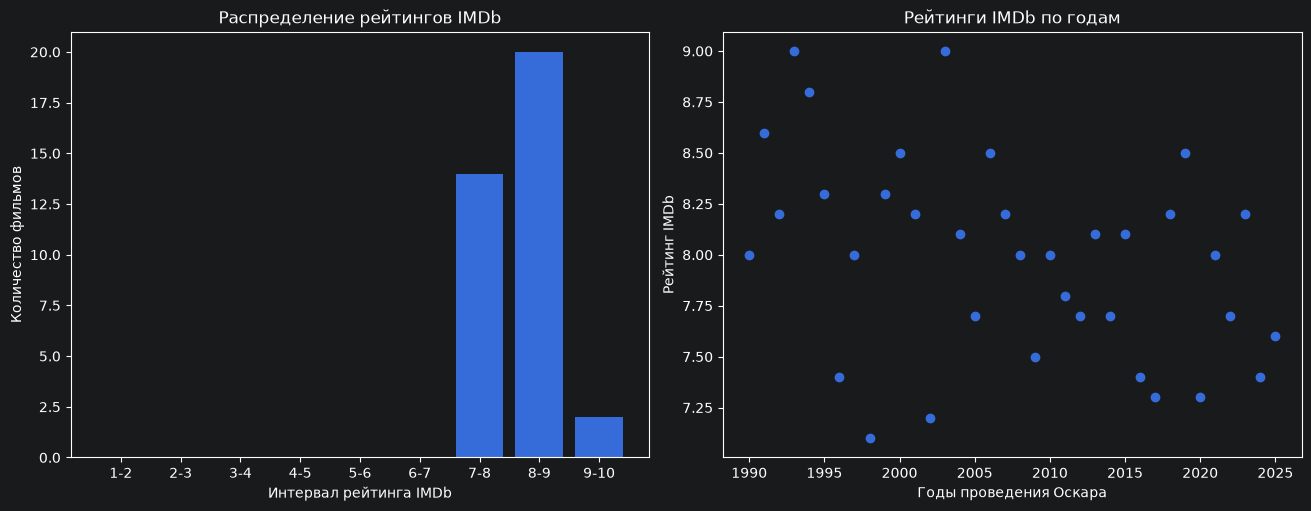

In [3]:
from modules.visualization import draw_rating_bar, draw_rating_scatter
import matplotlib.pyplot as plt

fig, axes = plt.subplots(
    nrows=1,
    ncols=2,
    figsize=(13, 5),
    layout='constrained'
)

draw_rating_bar(best_distribution, axes[0])
draw_rating_scatter(best_films, axes[1])

plt.show()
